In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import os

from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.ensemble import AdaBoostClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    auc,
    roc_auc_score
)

from sklearn.preprocessing import label_binarize

from IPython.display import display

In [2]:
X_train = pd.read_csv("../../../data/processed/X_train.csv")
X_test = pd.read_csv("../../../data/processed/X_test.csv")

y_train = pd.read_csv("../../../data/processed/y_train.csv").squeeze()
y_test = pd.read_csv("../../../data/processed/y_test.csv").squeeze()

print("Dados carregados!")
print("Treino:", X_train.shape)
print("Teste:", X_test.shape)

Dados carregados!
Treino: (10648, 24)
Teste: (4564, 24)


In [3]:
modelos = {
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=100,
        random_state=42
    ),

    "AdaBoost": AdaBoostClassifier(
        n_estimators=100,
        random_state=42
    )
}

In [4]:
resultados = {}

for nome, modelo in modelos.items():
    print(f"Treinando {nome}...")

    modelo.fit(X_train, y_train)

    previsoes = modelo.predict(X_test)

    resultados[nome] = {
        "modelo": modelo,
        "previsoes": previsoes,
        "accuracy": accuracy_score(y_test, previsoes),
        "precision": precision_score(
            y_test, previsoes, average="weighted", zero_division=0
        ),
        "recall": recall_score(
            y_test, previsoes, average="weighted", zero_division=0
        ),
        "f1": f1_score(
            y_test, previsoes, average="weighted", zero_division=0
        )
    }

    print(f"{nome} finalizado!\n")

Treinando Random Forest...
Random Forest finalizado!

Treinando Gradient Boosting...
Gradient Boosting finalizado!

Treinando AdaBoost...
AdaBoost finalizado!



In [5]:
tabela_resultados = pd.DataFrame([
    {
        "Modelo": nome,
        "Acurácia": dados["accuracy"],
        "Precisão": dados["precision"],
        "Recall": dados["recall"],
        "F1-Score": dados["f1"]
    }
    for nome, dados in resultados.items()
])

tabela_resultados = tabela_resultados.sort_values(
    by="F1-Score",
    ascending=False
)

display(tabela_resultados)

,Modelo,Acurácia,Precisão,Recall,F1-Score
1,Gradient Boosting,0.999562,0.999566,0.999562,0.999558
0,Random Forest,0.992770,0.992783,0.992770,0.992476
2,AdaBoost,0.937555,0.948689,0.937555,0.939107


In [6]:
for nome, dados in resultados.items():
    nome_arquivo = nome.lower().replace(" ", "_")

    joblib.dump(
        dados["modelo"],
        f"../../../models/{nome_arquivo}.pkl"
    )

print("Modelos salvos!")

Modelos salvos!


In [7]:
importancias = {}

for nome, dados in resultados.items():
    modelo = dados["modelo"]

    importancias[nome] = modelo.feature_importances_

feature_importance = pd.DataFrame(
    importancias,
    index=X_train.columns
)

feature_importance.index.name = "Atributo"

display(feature_importance)

,Random Forest,Gradient Boosting,AdaBoost
Atributo,,,
GENDER,0.031762,9.366888e-02,0.066260
WBC,0.005621,1.123585e-05,0.000000
NE#,0.006521,4.147022e-05,0.000000
LY#,0.008435,6.520974e-05,0.000000
MO#,0.006568,6.244019e-05,0.000000
EO#,0.005497,2.383169e-09,0.000000
BA#,0.004357,8.882825e-05,0.000000
RBC,0.064084,5.030451e-03,0.000000
HGB,0.317650,7.297490e-01,0.227608


In [11]:
feature_importance["Media"] = feature_importance.mean(axis=1)

top_10 = feature_importance.sort_values(
    by="Media",
    ascending=False
).head(10)

display(top_10.style.format("{:.6f}"))

,Random Forest,Gradient Boosting,AdaBoost,Media
Atributo,,,,
HGB,0.317650,0.729749,0.227608,0.425002
TSD,0.090175,0.123456,0.151176,0.121602
FOLATE,0.018374,0.002842,0.294826,0.105347
FERRITTE,0.032882,0.033908,0.134369,0.067053
GENDER,0.031762,0.093669,0.066260,0.063897
HCT,0.165334,0.000000,0.000000,0.055111
B12,0.022203,0.010567,0.125762,0.052844
RBC,0.064084,0.005030,0.000000,0.023038
SD,0.055696,0.000106,0.000000,0.018600


<Figure size 1200x700 with 0 Axes>

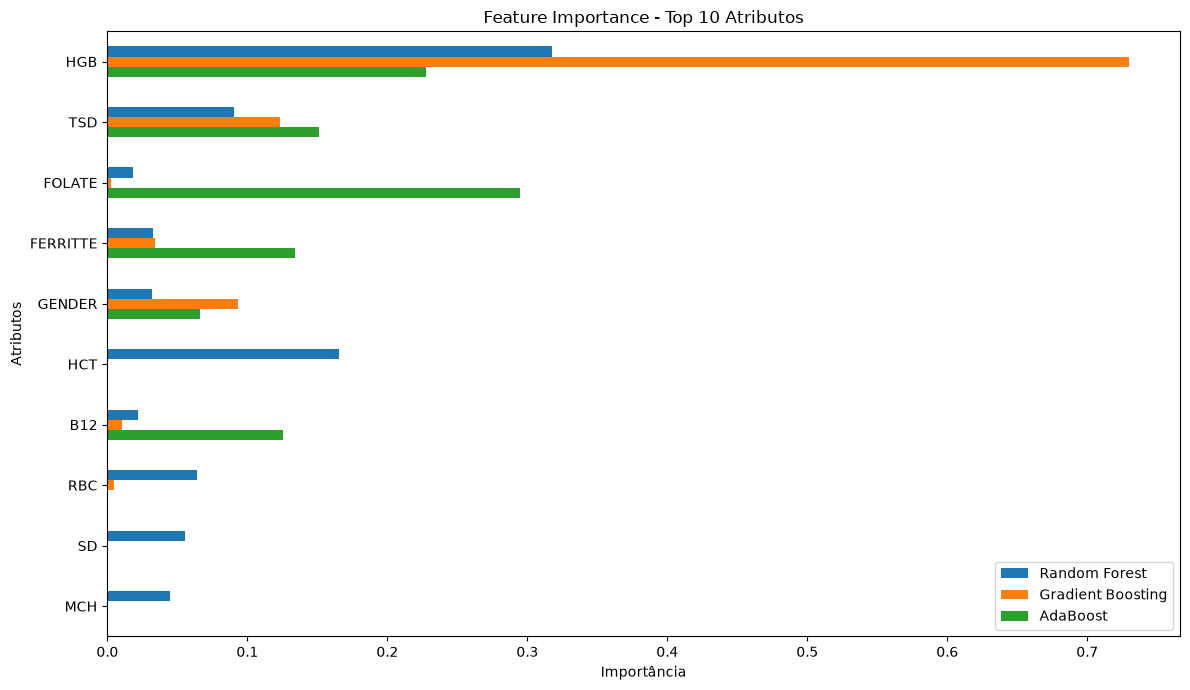

In [9]:
plt.figure(figsize=(12, 7))

top_10[["Random Forest", "Gradient Boosting", "AdaBoost"]].plot(
    kind="barh",
    figsize=(12, 7)
)

plt.title("Feature Importance - Top 10 Atributos")
plt.xlabel("Importância")
plt.ylabel("Atributos")
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

<Figure size 1200x700 with 0 Axes>

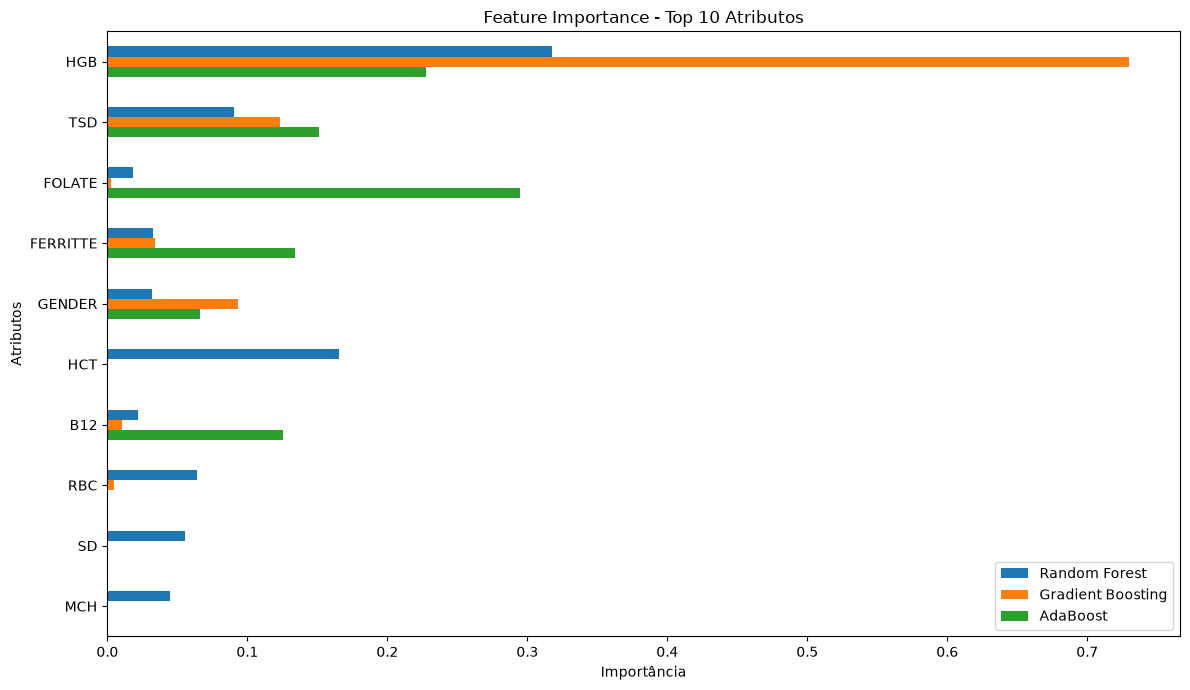

In [12]:
os.makedirs("../../../outputs/figures", exist_ok=True)
os.makedirs("../../../outputs/metrics", exist_ok=True)

top_10.to_csv(
    "../../../outputs/metrics/feature_importance.csv"
)

plt.figure(figsize=(12, 7))

top_10[["Random Forest", "Gradient Boosting", "AdaBoost"]].plot(
    kind="barh",
    figsize=(12, 7)
)

plt.title("Feature Importance - Top 10 Atributos")
plt.xlabel("Importância")
plt.ylabel("Atributos")
plt.gca().invert_yaxis()
plt.tight_layout()

plt.savefig(
    "../../../outputs/figures/feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

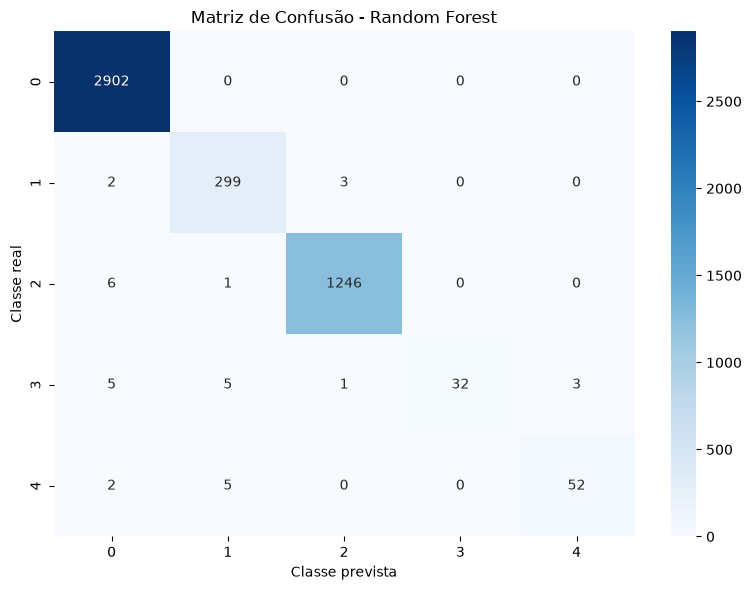

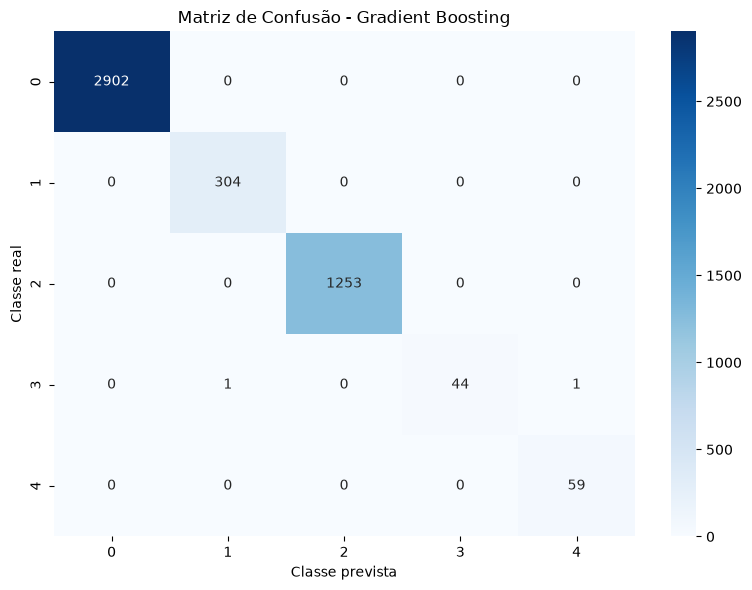

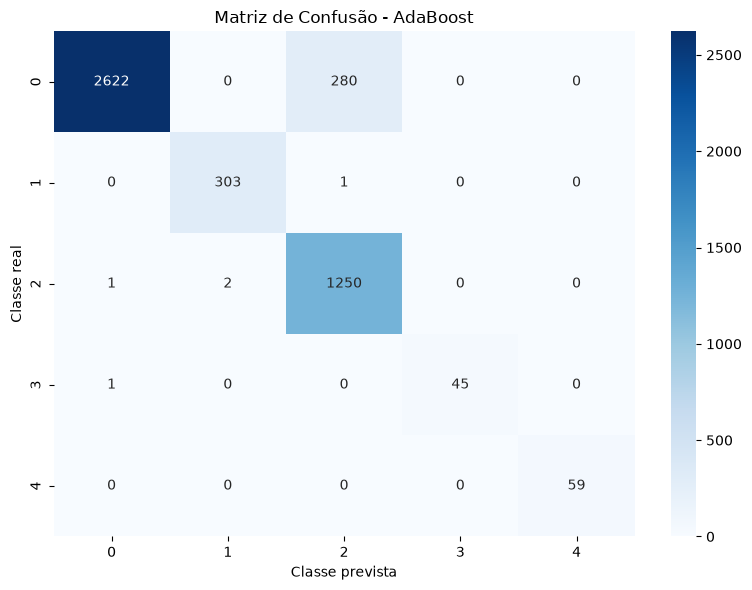

In [15]:
classes = sorted(y_test.unique())

os.makedirs("../../../outputs/figures", exist_ok=True)

for nome, dados in resultados.items():

    matriz = confusion_matrix(
        y_test,
        dados["previsoes"],
        labels=classes
    )

    plt.figure(figsize=(8, 6))

    sns.heatmap(
        matriz,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=classes,
        yticklabels=classes
    )

    plt.title(f"Matriz de Confusão - {nome}")
    plt.xlabel("Classe prevista")
    plt.ylabel("Classe real")

    plt.tight_layout()

    nome_arquivo = nome.lower().replace(" ", "_")

    plt.savefig(
        f"../../../outputs/figures/confusion_matrix_{nome_arquivo}.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

In [17]:
classes = sorted(y_test.unique())

y_test_bin = label_binarize(
    y_test,
    classes=classes
)

print("Classes:", classes)
print("Formato de y_test_bin:", y_test_bin.shape)

Classes: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
Formato de y_test_bin: (4564, 5)


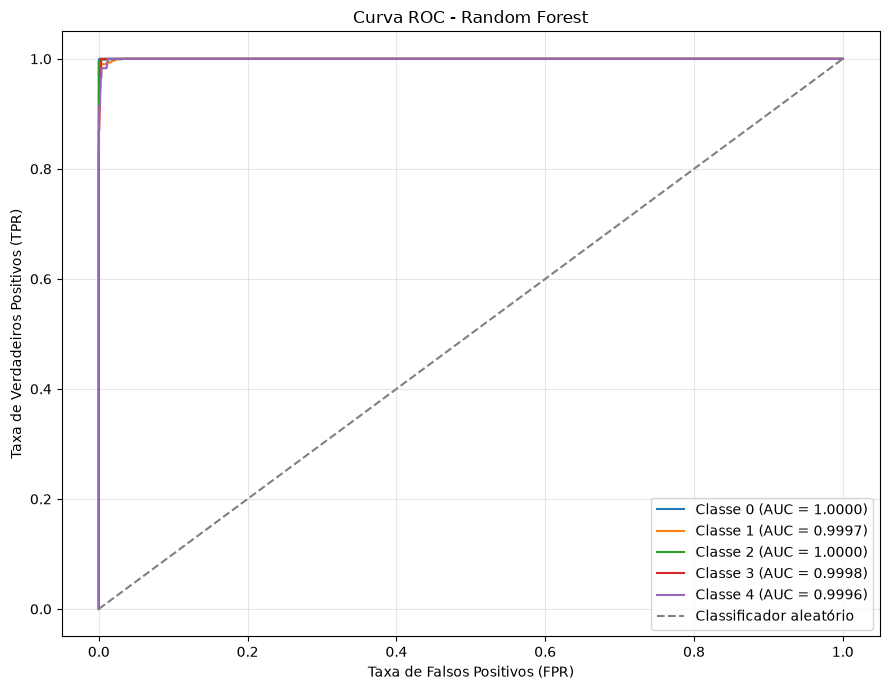

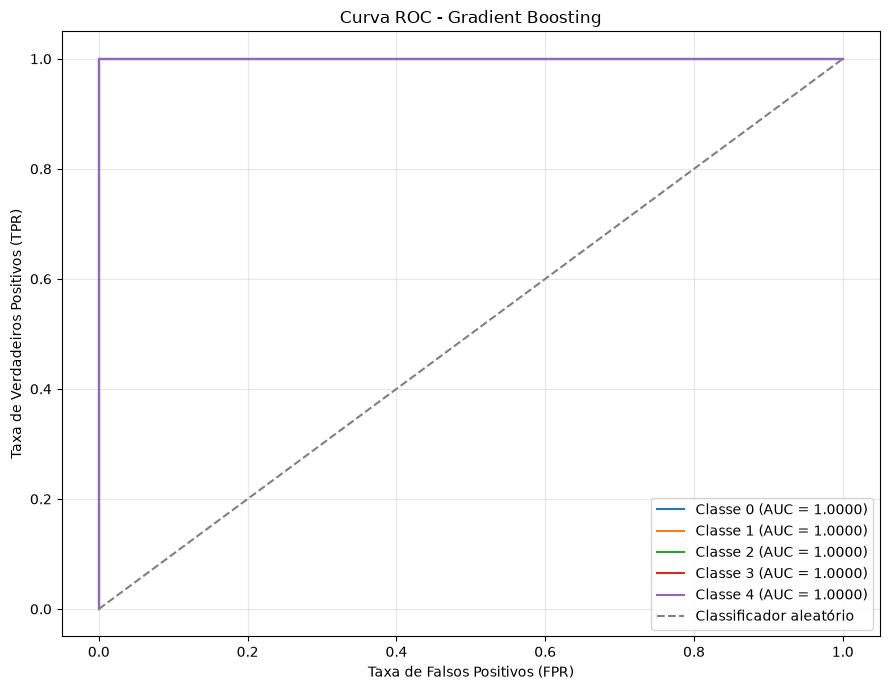

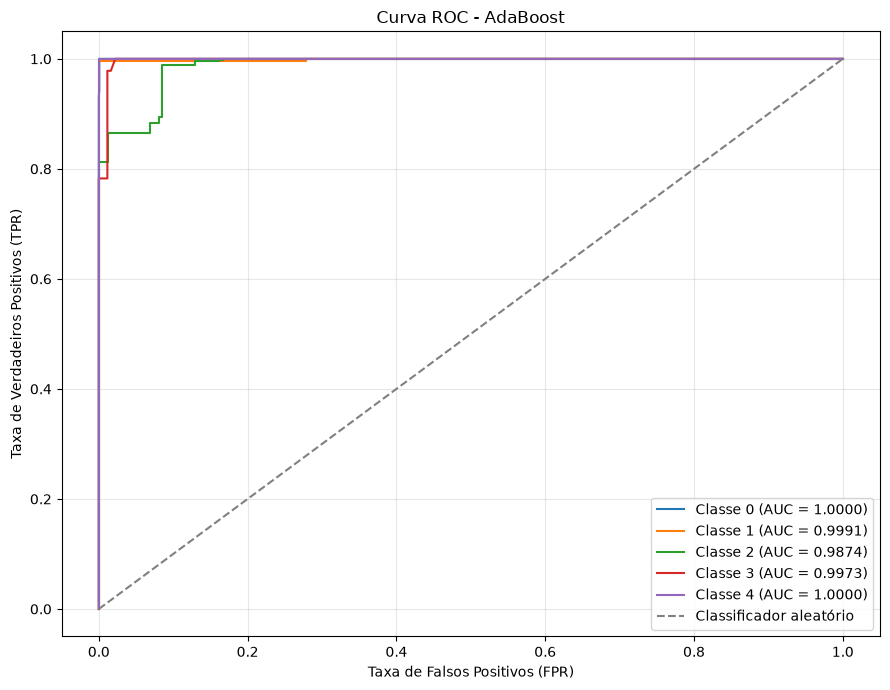

In [18]:
os.makedirs("../../../outputs/figures", exist_ok=True)
os.makedirs("../../../outputs/metrics", exist_ok=True)

resultados_roc = {}

for nome, dados in resultados.items():

    modelo = dados["modelo"]

    # Probabilidades previstas para cada classe
    probabilidades = modelo.predict_proba(X_test)

    plt.figure(figsize=(9, 7))

    auc_classes = {}

    for i, classe in enumerate(classes):

        fpr, tpr, _ = roc_curve(
            y_test_bin[:, i],
            probabilidades[:, i]
        )

        valor_auc = auc(fpr, tpr)

        auc_classes[classe] = valor_auc

        plt.plot(
            fpr,
            tpr,
            label=f"Classe {classe} (AUC = {valor_auc:.4f})"
        )

    # Linha de referência
    plt.plot(
        [0, 1],
        [0, 1],
        linestyle="--",
        color="gray",
        label="Classificador aleatório"
    )

    plt.title(f"Curva ROC - {nome}")
    plt.xlabel("Taxa de Falsos Positivos (FPR)")
    plt.ylabel("Taxa de Verdadeiros Positivos (TPR)")

    plt.legend(loc="lower right")
    plt.grid(alpha=0.3)
    plt.tight_layout()

    nome_arquivo = nome.lower().replace(" ", "_")

    plt.savefig(
        f"../../../outputs/figures/roc_{nome_arquivo}.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    resultados_roc[nome] = auc_classes

In [19]:
tabela_roc = pd.DataFrame(resultados_roc)

tabela_roc.index.name = "Classe"

tabela_roc.loc["Média"] = tabela_roc.mean(axis=0)

display(tabela_roc.style.format("{:.6f}"))

tabela_roc.to_csv(
    "../../../outputs/metrics/roc_auc_comparison.csv"
)

print("Resultados ROC salvos!")

,Random Forest,Gradient Boosting,AdaBoost
Classe,,,
0,0.999998,1.000000,0.999962
1,0.999739,0.999999,0.999083
2,0.999958,1.000000,0.987441
3,0.999781,0.999990,0.997332
4,0.999614,1.000000,1.000000
Média,0.999818,0.999998,0.996764


Resultados ROC salvos!
